# Etapa II - EDA y verificación

Análisis exploratorio y limpieza de **containers-2022-07-27.csv**: ubicación e información sobre contenedores para la recepción de residuos reciclables (dataset *Contenedores, programas para la recepción de residuos reciclables y condiciones de recepción (¿Dónde Reciclo?)*, catálogo de datos abiertos de Uruguay).

El original se lee desde `docs/Datos/Dataset - original` y **no se modifica**.

1. Calidad del original: nulos, duplicados, anomalías de coordenadas y de departamento, outliers.
2. Limpieza y exportación a `docs/Datos/Dataset - limpio/containers-limpio.parquet`.
3. Revisión de calidad después de la limpieza.
4. Mapa folium con los contenedores visibles, agrupados por departamento.
5. Un DataFrame por departamento.

In [1]:
from pathlib import Path
import re
import unicodedata

import numpy as np
import pandas as pd
import folium
from folium.plugins import MarkerCluster

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

# El notebook corre desde: docs/Datos/Análisis de datos/Etapa II - EDA y verificación
CARPETA_NOTEBOOK = Path.cwd()
CARPETA_DATOS = CARPETA_NOTEBOOK.parents[1]  # docs/Datos
ARCHIVO_ORIGINAL = CARPETA_DATOS / "Dataset - original" / "containers-2022-07-27.csv"
CARPETA_LIMPIO = CARPETA_DATOS / "Dataset - limpio"
ARCHIVO_LIMPIO = CARPETA_LIMPIO / "containers-limpio.parquet"
ARCHIVO_MAPA = CARPETA_NOTEBOOK / "mapa-contenedores.html"

# Límites aproximados de Uruguay para validar coordenadas (lat, lon)
LAT_MIN, LAT_MAX = -35.1, -30.0
LON_MIN, LON_MAX = -58.5, -53.0

DEPARTAMENTOS = [
    "Artigas", "Canelones", "Cerro Largo", "Colonia", "Durazno", "Flores", "Florida",
    "Lavalleja", "Maldonado", "Montevideo", "Paysandú", "Río Negro", "Rivera", "Rocha",
    "Salto", "San José", "Soriano", "Tacuarembó", "Treinta y Tres",
]


def en_uruguay(lat, lon):
    """True si cada par (lat, lon) cae dentro del rectángulo aproximado de Uruguay."""
    return lat.between(LAT_MIN, LAT_MAX) & lon.between(LON_MIN, LON_MAX)


def atipicos_iqr(serie):
    """Marca los valores fuera de 1.5 veces el rango intercuartil."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)

In [2]:
df_raw = pd.read_csv(ARCHIVO_ORIGINAL, encoding="utf-8-sig")
print("Filas y columnas:", df_raw.shape)
df_raw.head(3)

Filas y columnas: (2423, 16)


,Id,External,Latitude,Longitude,Site,Address,Location,State,Site type,Public site,Created at,Updated at,Hidden,Latlon,Information,Custom icon active
0,11780,NaN,-34.753762,-55.845820,NaN,"Ruta 87, Manzana 157, Solar 16. Entre Tapes y ...",Salinas,Canelones,NaN,True,2022-07-26 20:21:39 UTC,2022-07-26 20:32:15 UTC,False,NaN,Compostar para utilizar en huerta comunitaria ...,False
1,11779,NaN,-34.592136,-54.124148,Club de La Pedrera (martes previa coordinación...,NaN,La Paloma,Rocha,NaN,True,2022-07-25 19:18:50 UTC,2022-07-26 20:33:53 UTC,False,NaN,Se recicla el residuo ferroso y plástico que c...,False
2,11778,NaN,-34.618292,-54.151271,Placita de Arachania (sábados previa coordinac...,NaN,La Paloma,Rocha,NaN,True,2022-07-25 19:13:49 UTC,2022-07-26 20:34:12 UTC,False,NaN,Se recicla el residuo ferroso y plástico que c...,False


## 1. Calidad del archivo original

In [3]:
# Valores faltantes por columna
nulos = pd.DataFrame({"nulos": df_raw.isna().sum(), "% nulos": df_raw.isna().mean().mul(100).round(1)})
nulos[nulos["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,% nulos
Latlon,2423,100.0
Information,2254,93.0
Custom icon active,2225,91.8
Location,1536,63.4
Site type,996,41.1
External,825,34.0
Site,392,16.2
Address,377,15.6
State,2,0.1
Longitude,1,0.0


In [4]:
print("Filas duplicadas exactas:", df_raw.duplicated().sum())
print("Ids repetidos:", df_raw["Id"].duplicated().sum())

columnas_contenido = ["Latitude", "Longitude", "Site", "Address", "State", "Site type", "Information"]
print("Repetidos de contenido (sin Id ni fechas):", df_raw.duplicated(columnas_contenido).sum())
print("Filas que comparten coordenadas exactas:", df_raw.duplicated(["Latitude", "Longitude"], keep=False).sum())

Filas duplicadas exactas: 0
Ids repetidos: 0
Repetidos de contenido (sin Id ni fechas): 14
Filas que comparten coordenadas exactas: 47


In [5]:
# Departamentos tal como vienen: repr muestra espacios sobrantes y errores de escritura
df_raw["State"].map(repr).value_counts(dropna=False)

State
'Montevideo'               1275
'Montevideo '               357
'Canelones'                 275
'Colonia'                    70
'Maldonado'                  65
'Paysandú'                   57
'Flores'                     56
'Rocha'                      39
'Tacuarembó'                 33
'Salto'                      31
'Rivera'                     27
'Lavalleja'                  25
'Florida'                    20
'Soriano'                    18
'Cerro Largo'                12
'Artigas'                    11
'San José'                   11
'Treinta y Tres'             11
'Durazno'                    10
'Río Negro'                  10
nan                           2
'Paysandu'                    1
'Soriano '                    1
'San Jose'                    1
'Rio Negro'                   1
'La Floresta-Canelones'       1
'Flroes'                      1
'Tacaurembó'                  1
'Treinta y Tres '             1
Name: count, dtype: int64

In [6]:
lat, lon = df_raw["Latitude"], df_raw["Longitude"]

anomalias_coordenadas = pd.Series({
    "Fuera de Uruguay (incluye faltantes)": int((~en_uruguay(lat, lon)).sum()),
    "  Latitud y longitud intercambiadas": int((~en_uruguay(lat, lon) & en_uruguay(lon, lat)).sum()),
    "  Longitud con signo positivo": int(((lon > 0) & en_uruguay(lat, -lon)).sum()),
    "  Latitud o longitud igual a 0": int(((lat == 0) | (lon == 0)).sum()),
    "  Longitud faltante": int(lon.isna().sum()),
})
print("Atípicos IQR en latitud:", int(atipicos_iqr(lat).sum()))
print("Atípicos IQR en longitud:", int(atipicos_iqr(lon).sum()))
anomalias_coordenadas

Atípicos IQR en latitud: 526
Atípicos IQR en longitud: 674


Fuera de Uruguay (incluye faltantes)    51
  Latitud y longitud intercambiadas     44
  Longitud con signo positivo            1
  Latitud o longitud igual a 0           1
  Longitud faltante                      1
dtype: int64

In [7]:
# Localidades con muchos más contenedores que el resto (outliers de concentración)
por_localidad = df_raw["Location"].value_counts()
print("Localidades distintas:", por_localidad.size)
print("Atípicos IQR entre localidades:", int(atipicos_iqr(por_localidad).sum()))
por_localidad[atipicos_iqr(por_localidad)]

Localidades distintas: 299
Atípicos IQR entre localidades: 23


Location
Montevideo         64
Colonia            45
Paysandú           44
Trinidad           43
Maldonado          28
Salto              26
Rivera             17
Canelones          13
Mariscala          13
Ismael Cortinas    12
Punta del Este     12
Santa Rosa          9
Santa Lucía         9
San Jacinto         8
Salinas             8
Sauce               8
Las Piedras         8
La Paloma           8
ATLANTIDA           7
CANELONES           7
San Bautista        7
Migues              7
San Ramón           7
Name: count, dtype: int64

In [8]:
print(pd.crosstab(df_raw["Hidden"], df_raw["Public site"], margins=True))

creado = pd.to_datetime(df_raw["Created at"].str.replace(" UTC", ""), utc=True)
actualizado = pd.to_datetime(df_raw["Updated at"].str.replace(" UTC", ""), utc=True)
print("Actualizado antes que creado:", int((actualizado < creado).sum()))
print("Rango de creación:", creado.min(), "→", creado.max())

Public site  False  True   All
Hidden                        
False            9  2207  2216
True             0   207   207
All              9  2414  2423
Actualizado antes que creado: 0
Rango de creación: 2020-07-08 21:35:12+00:00 → 2022-07-26 20:21:39+00:00


## 2. Limpieza

Reglas:
- **Texto:** se quitan espacios sobrantes y dobles, y las celdas vacías pasan a faltantes.
- **Departamento:** se unifican variantes con y sin tildes, y errores de escritura. Si falta, se completa solo cuando la localidad aparece en un único departamento.
- **Localidad:** se unifican mayúsculas y tildes (ATLANTIDA y Atlántida) con la forma más frecuente.
- **Coordenadas:** se corrigen las intercambiadas y el signo de longitud. Lo que sigue fuera de Uruguay queda sin coordenadas. No se inventan valores.
- **Visibilidad:** `visible` es verdadero cuando el sitio no está oculto y es público (misma regla que la API).
- **Repetidos:** no se borran. Se marcan en `posible_duplicado` porque dos contenedores pueden estar en el mismo local.
- `Latlon` está 100 % vacía y se descarta.

In [9]:
df = df_raw.copy()

# Texto: espacios sobrantes y dobles, celdas vacías como faltantes
for col in ["Site", "Address", "Location", "State", "Site type", "Information"]:
    df[col] = df[col].str.strip().str.replace(r"\s+", " ", regex=True).replace("", np.nan)

In [10]:
def clave(texto):
    """Nombre en minúsculas, sin tildes ni signos: sirve para comparar variantes."""
    sin_tildes = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z]", "", sin_tildes.lower())


CANONICO = {clave(d): d for d in DEPARTAMENTOS}
ESCRITURAS_ERRONEAS = {
    "Flroes": "Flores",
    "Tacaurembó": "Tacuarembó",
    "La Floresta-Canelones": "Canelones",
}


def normalizar_departamento(valor):
    if pd.isna(valor):
        return np.nan
    if valor in ESCRITURAS_ERRONEAS:
        return ESCRITURAS_ERRONEAS[valor]
    return CANONICO.get(clave(valor), valor)


df["State"] = df["State"].map(normalizar_departamento)
print("Departamentos no reconocidos:", sorted(set(df["State"].dropna()) - set(DEPARTAMENTOS)))

# Faltantes: solo si la localidad pertenece a un único departamento
depto_por_localidad = (
    df.dropna(subset=["State", "Location"])
    .groupby("Location")["State"]
    .agg(lambda s: s.iloc[0] if s.nunique() == 1 else np.nan)
    .dropna()
)
faltan = df["State"].isna()
df.loc[faltan, "State"] = df.loc[faltan, "Location"].map(depto_por_localidad)
print("Departamentos completados por localidad:", int(faltan.sum() - df["State"].isna().sum()))

Departamentos no reconocidos: []
Departamentos completados por localidad: 1


In [11]:
lat, lon = df["Latitude"], df["Longitude"]

# 1) Latitud y longitud intercambiadas (caso Colonia: lat -57.8, lon -34.4)
intercambio = ~en_uruguay(lat, lon) & en_uruguay(lon, lat)
lat, lon = lat.where(~intercambio, df["Longitude"]), lon.where(~intercambio, df["Latitude"])

# 2) Longitud con signo positivo (por ejemplo 55.98 → -55.98)
signo = (lon > 0) & en_uruguay(lat, -lon)
lon = lon.where(~signo, -lon)

# 3) Lo que sigue fuera de Uruguay (0, -5.4e16, faltantes) queda sin coordenadas
valida = en_uruguay(lat, lon)
df["latitud"] = lat.where(valida)
df["longitud"] = lon.where(valida)
df["coordenada_valida"] = valida
df["coordenada_corregida"] = np.select(
    [intercambio, signo], ["intercambiada", "signo de longitud"], default=""
)
df["coordenada_corregida"] = df["coordenada_corregida"].replace("", np.nan)

In [12]:
# Localidades: unificar mayúsculas y tildes (ATLANTIDA y Atlántida) con la forma más frecuente
formas = df["Location"].dropna().value_counts()
forma_canonica = formas.groupby(formas.index.map(clave)).idxmax()
df["Location"] = df["Location"].map(lambda v: forma_canonica.get(clave(v), v) if pd.notna(v) else v)

In [13]:
df["visible"] = ~df["Hidden"] & df["Public site"]

creado = pd.to_datetime(df["Created at"].str.replace(" UTC", ""), utc=True)
actualizado = pd.to_datetime(df["Updated at"].str.replace(" UTC", ""), utc=True)

# Se marcan para revisión; no se borran
df["posible_duplicado"] = df.duplicated(["latitud", "longitud", "Site", "Address", "State"], keep=False)

In [14]:
limpio = pd.DataFrame({
    "id": df["Id"],
    "id_externo": df["External"].astype("Int64"),
    "latitud": df["latitud"],
    "longitud": df["longitud"],
    "coordenada_valida": df["coordenada_valida"],
    "coordenada_corregida": df["coordenada_corregida"],
    "sitio": df["Site"],
    "direccion": df["Address"],
    "localidad": df["Location"],
    "departamento": df["State"],
    "tipo_sitio": df["Site type"],
    "sitio_publico": df["Public site"],
    "oculto": df["Hidden"],
    "visible": df["visible"],
    "posible_duplicado": df["posible_duplicado"],
    "informacion": df["Information"],
    "icono_propio": df["Custom icon active"].astype("boolean"),
    "creado_en": creado,
    "actualizado_en": actualizado,
})
limpio.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2423 entries, 0 to 2422
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   id                    2423 non-null   int64              
 1   id_externo            1598 non-null   Int64              
 2   latitud               2417 non-null   float64            
 3   longitud              2417 non-null   float64            
 4   coordenada_valida     2423 non-null   bool               
 5   coordenada_corregida  45 non-null     object             
 6   sitio                 2031 non-null   object             
 7   direccion             2046 non-null   object             
 8   localidad             887 non-null    object             
 9   departamento          2422 non-null   object             
 10  tipo_sitio            1427 non-null   object             
 11  sitio_publico         2423 non-null   bool               
 12  oculto

In [15]:
resumen_limpieza = pd.Series({
    "Filas": len(limpio),
    "Departamentos distintos (antes)": df_raw["State"].nunique(),
    "Departamentos distintos (después)": limpio["departamento"].nunique(),
    "Sin departamento (después)": int(limpio["departamento"].isna().sum()),
    "Localidades distintas (antes)": df_raw["Location"].nunique(),
    "Localidades distintas (después)": limpio["localidad"].nunique(),
    "Coordenadas válidas (antes)": int(en_uruguay(df_raw["Latitude"], df_raw["Longitude"]).sum()),
    "Coordenadas válidas (después)": int(limpio["coordenada_valida"].sum()),
    "Latitud y longitud intercambiadas corregidas": int(intercambio.sum()),
    "Signo de longitud corregido": int(signo.sum()),
    "Visibles (no ocultos y públicos)": int(limpio["visible"].sum()),
    "Filas marcadas como posible duplicado": int(limpio["posible_duplicado"].sum()),
})
resumen_limpieza

Filas                                           2423
Departamentos distintos (antes)                   28
Departamentos distintos (después)                 19
Sin departamento (después)                         1
Localidades distintas (antes)                    299
Localidades distintas (después)                  261
Coordenadas válidas (antes)                     2372
Coordenadas válidas (después)                   2417
Latitud y longitud intercambiadas corregidas      44
Signo de longitud corregido                        1
Visibles (no ocultos y públicos)                2207
Filas marcadas como posible duplicado             26
dtype: int64

In [16]:
assert limpio["departamento"].dropna().isin(DEPARTAMENTOS).all()

CARPETA_LIMPIO.mkdir(parents=True, exist_ok=True)
limpio.to_parquet(ARCHIVO_LIMPIO, index=False)

verificacion = pd.read_parquet(ARCHIVO_LIMPIO)
print("Guardado:", ARCHIVO_LIMPIO)
print("Filas y columnas leídas:", verificacion.shape, "| coincide con el DataFrame:", verificacion.shape == limpio.shape)

Guardado: C:\Users\Usuario\Documents\Proyecto de Datos\Proyecto - Residuos Montevideo DATA URUGUAY\docs\Datos\Dataset - limpio\containers-limpio.parquet
Filas y columnas leídas: (2423, 19) | coincide con el DataFrame: True


## 3. Calidad después de la limpieza

In [17]:
nulos_limpio = pd.DataFrame({"nulos": limpio.isna().sum(), "% nulos": limpio.isna().mean().mul(100).round(1)})
nulos_limpio[nulos_limpio["nulos"] > 0].sort_values("nulos", ascending=False)

,nulos,% nulos
coordenada_corregida,2378,98.1
informacion,2254,93.0
icono_propio,2225,91.8
localidad,1536,63.4
tipo_sitio,996,41.1
id_externo,825,34.0
sitio,392,16.2
direccion,377,15.6
latitud,6,0.2
longitud,6,0.2


In [18]:
print("Atípicos IQR en latitud (válidas):", int(atipicos_iqr(limpio["latitud"].dropna()).sum()))
print("Atípicos IQR en longitud (válidas):", int(atipicos_iqr(limpio["longitud"].dropna()).sum()))
print("Duplicados exactos de contenido:", int(limpio.drop(columns=["id", "id_externo", "creado_en", "actualizado_en"]).duplicated().sum()))
limpio["departamento"].value_counts(dropna=False)

Atípicos IQR en latitud (válidas): 495
Atípicos IQR en longitud (válidas): 697
Duplicados exactos de contenido: 14


departamento
Montevideo        1632
Canelones          276
Colonia             71
Maldonado           65
Paysandú            58
Flores              57
Rocha               39
Tacuarembó          34
Salto               31
Rivera              27
Lavalleja           25
Florida             20
Soriano             19
Treinta y Tres      12
San José            12
Cerro Largo         12
Artigas             11
Río Negro           11
Durazno             10
NaN                  1
Name: count, dtype: int64

## 4. Mapa de contenedores visibles, agrupados por departamento

In [19]:
mapa_datos = limpio[limpio["visible"] & limpio["coordenada_valida"] & limpio["departamento"].notna()].copy()
mapa_datos[["sitio", "direccion", "tipo_sitio"]] = mapa_datos[["sitio", "direccion", "tipo_sitio"]].fillna("sin dato")

m = folium.Map(location=[-32.8, -56.0], zoom_start=7)

# Una capa por departamento; dentro, los marcadores se agrupan al alejar el mapa
for departamento, grupo in mapa_datos.groupby("departamento"):
    capa = folium.FeatureGroup(name=f"{departamento} ({len(grupo)})")
    cluster = MarkerCluster().add_to(capa)
    for fila in grupo.itertuples():
        popup = f"<b>{fila.sitio}</b><br>{fila.direccion}<br>{fila.tipo_sitio}"
        folium.Marker([fila.latitud, fila.longitud], popup=popup).add_to(cluster)
    capa.add_to(m)

folium.LayerControl(collapsed=False).add_to(m)
m.save(ARCHIVO_MAPA)
print("Marcadores:", len(mapa_datos), "| mapa guardado en:", ARCHIVO_MAPA)
m

Marcadores: 2201 | mapa guardado en: C:\Users\Usuario\Documents\Proyecto de Datos\Proyecto - Residuos Montevideo DATA URUGUAY\docs\Datos\Análisis de datos\Etapa II - EDA y verificación\mapa-contenedores.html


## 5. Un DataFrame por departamento

In [20]:
# Solo contenedores visibles, con su departamento
contenedores_por_departamento = {
    departamento: grupo.reset_index(drop=True)
    for departamento, grupo in limpio[limpio["visible"] & limpio["departamento"].notna()].groupby("departamento")
}

resumen_departamentos = (
    pd.DataFrame([
        {"departamento": d, "contenedores": len(g), "con coordenadas válidas": int(g["coordenada_valida"].sum())}
        for d, g in contenedores_por_departamento.items()
    ])
    .sort_values("contenedores", ascending=False)
    .reset_index(drop=True)
)
resumen_departamentos

,departamento,contenedores,con coordenadas válidas
0,Montevideo,1567,1564
1,Canelones,247,246
2,Colonia,61,61
3,Flores,56,56
4,Paysandú,55,55
5,Rocha,33,32
6,Tacuarembó,31,31
7,Salto,29,28
8,Lavalleja,20,20
9,Maldonado,16,16


In [21]:
# Ejemplo: el DataFrame de Rocha
contenedores_por_departamento.get("Rocha").head()

,id,id_externo,latitud,longitud,coordenada_valida,coordenada_corregida,sitio,direccion,localidad,departamento,tipo_sitio,sitio_publico,oculto,visible,posible_duplicado,informacion,icono_propio,creado_en,actualizado_en
0,11779,<NA>,-34.592136,-54.124148,True,NaN,Club de La Pedrera (martes previa coordinación...,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se recicla el residuo ferroso y plástico que c...,False,2022-07-25 19:18:50+00:00,2022-07-26 20:33:53+00:00
1,11778,<NA>,-34.618292,-54.151271,True,NaN,Placita de Arachania (sábados previa coordinac...,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se recicla el residuo ferroso y plástico que c...,False,2022-07-25 19:13:49+00:00,2022-07-26 20:34:12+00:00
2,11777,<NA>,-34.640561,-54.159035,True,NaN,Club Deportivo y Social La Aguada (previa coor...,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se reciben bicicletas en desuso y se reciclan ...,False,2022-07-25 19:12:10+00:00,2022-07-26 20:34:28+00:00
3,11776,<NA>,-34.658430,-54.158926,True,NaN,Municipio de La Paloma,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se reciben bicicletas en desuso y se reciclan ...,False,2022-07-25 19:08:06+00:00,2022-07-26 20:35:15+00:00
4,11775,<NA>,NaN,NaN,False,NaN,Piccola Marina,NaN,La Paloma,Rocha,NaN,True,False,True,False,Se reciben bicicletas en desuso y se reciclan ...,False,2022-07-25 15:58:54+00:00,2022-07-26 20:38:37+00:00


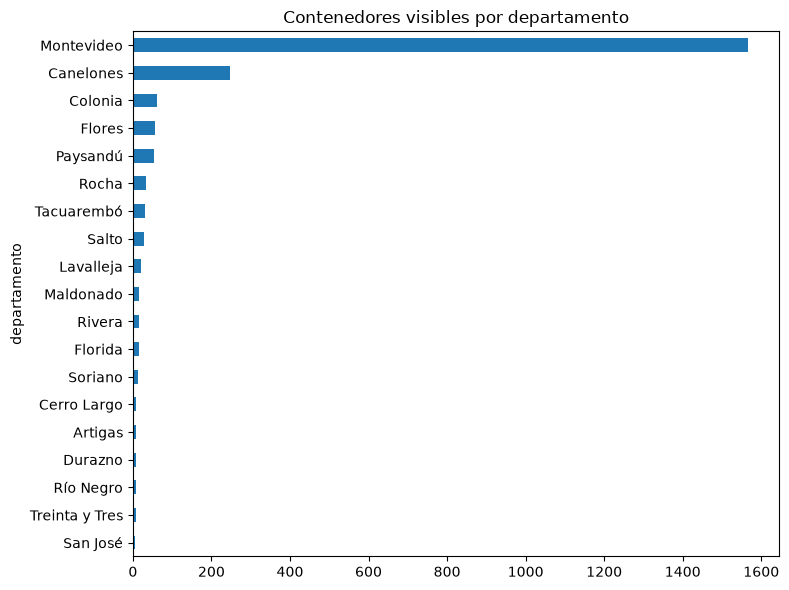

In [22]:
import matplotlib.pyplot as plt

ax = resumen_departamentos.set_index("departamento")["contenedores"].plot.barh(
    figsize=(8, 6), title="Contenedores visibles por departamento"
)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Hallazgos

**Estructura del original:** 2 423 filas y 16 columnas. `Latlon` está vacía en todas las filas y se descarta. `Information` (93 % vacía), `Custom icon active` (92 %), `Location` (63 %) y `Site type` (41 %) tienen muchos faltantes.

**Repetidos:** no hay filas exactamente iguales ni `Id` repetidos. Sí hay 14 filas repetidas en contenido (sin Id ni fechas) y 47 filas que comparten coordenadas exactas, muchas en el mismo local. Tras la limpieza, 26 filas quedan marcadas como `posible_duplicado` para revisar, sin borrarlas.

**Coordenadas:** 51 filas caen fuera de Uruguay o no tienen longitud. De ellas, 44 tienen latitud y longitud intercambiadas (todo el bloque de Colonia), 1 tiene signo positivo en la longitud, 1 tiene un 0 y 1 no tiene longitud. Tras la corrección, 2 417 filas tienen coordenadas válidas. Los 6 restantes quedan sin coordenadas y no aparecen en el mapa.

**Departamentos y localidades:** hay 28 escrituras de departamento para 19 departamentos reales (tildes, espacios, errores como «Flroes»). Una fila sin departamento se completa por su localidad; queda 1 sin departamento. Las localidades bajan de 299 a 261 al unificar mayúsculas y tildes.

**Visibilidad:** 2 207 contenedores son visibles (no ocultos y públicos). Los 207 ocultos y los 9 no públicos se conservan en el parquet con `visible = False`, y no entran en el mapa ni en los DataFrames por departamento.

**Outliers:** el criterio IQR marca cientos de puntos en latitud y longitud, pero eso refleja la dispersión geográfica del país y no errores. Los errores reales son los de coordenadas corregidos arriba. En localidades, el IQR marca 23 con muchos contenedores (Montevideo, Colonia, Paysandú, Trinidad).

**Concentración:** Montevideo concentra 1 567 de los 2 207 contenedores visibles (71 %), seguido por Canelones con 247.
